In [15]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.append(str(Path("..") / "src"))
from labliquidvision import LabLiquidVisionDataset

root = Path("..") / "data" / "LabLiquidVision" / "processed"
sample_id = "Cell_Flask_160mL_31ml_1105_0605"
ds = LabLiquidVisionDataset(root, ids=[sample_id])
sample = ds[0]
sample_dir = Path(sample["path"])
print(sample_dir)
print(sorted([p.name for p in sample_dir.iterdir()]))

../data/LabLiquidVision/processed/Cell_Flask_160mL_31ml_1105_0605
['Input_ContentDepth.npy', 'Input_ContentDepth_segmented.npy', 'Input_ContentDepth_segmented.png', 'Input_ContentMaskClean.npy', 'Input_ContentMaskClean.png', 'Input_DepthMap.npy', 'Input_DepthMap.png', 'Input_EmptyVessel_Depth.npy', 'Input_EmptyVessel_Depth_segmented.npy', 'Input_EmptyVessel_Depth_segmented.png', 'Input_RGBImage.npy', 'Input_RGBImage.png', 'Input_VesselMask.npy', 'Input_VesselMask.png', 'Input_color_liquid.txt', 'Input_vessel.txt', 'Input_visualize.png', 'Input_vol_liquid.txt', 'Input_vol_vessel.txt']


In [16]:
print("sample keys:")
for key in sorted(sample.keys()):
    print("-", key, type(sample[key]).__name__)

sample keys:
- color_liquid str
- content_depth ndarray
- content_depth_segmented ndarray
- content_mask_clean ndarray
- depth_map ndarray
- empty_vessel_depth ndarray
- empty_vessel_depth_segmented ndarray
- id str
- path str
- rgb ndarray
- vessel str
- vessel_mask ndarray
- vol_liquid float
- vol_vessel float


In [17]:
text_keys = ["color_liquid", "vessel", "vol_liquid", "vol_vessel"]
for key in text_keys:
    if key in sample:
        print(key, sample[key])

color_liquid red
vessel Cell_Flask_160mL
vol_liquid 31.0
vol_vessel 268.0


In [18]:
for key, value in sample.items():
    if isinstance(value, np.ndarray):
        print(key, value.shape, value.dtype)
        if key == "rgb":
            rgb = value

rgb (480, 640, 3) uint8
depth_map (480, 640) uint16
content_depth (480, 640) float16
content_depth_segmented (480, 640) float16
content_mask_clean (1, 480, 640) int64
empty_vessel_depth (480, 640) float16
empty_vessel_depth_segmented (480, 640) float16
vessel_mask (1, 480, 640) int64


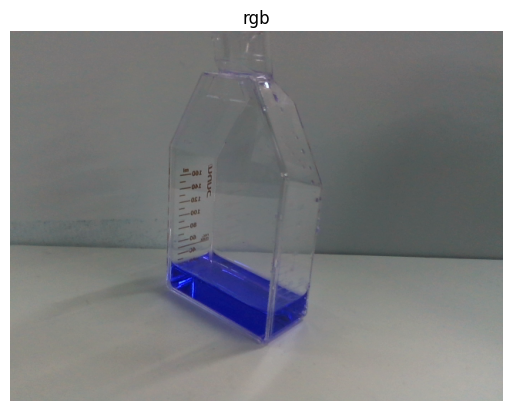

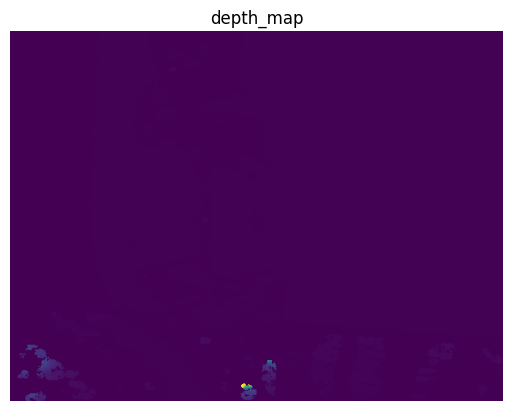

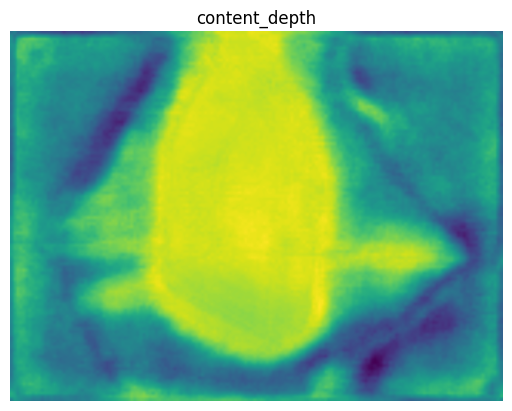

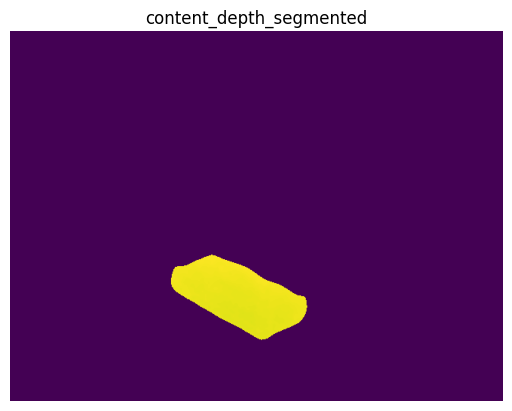

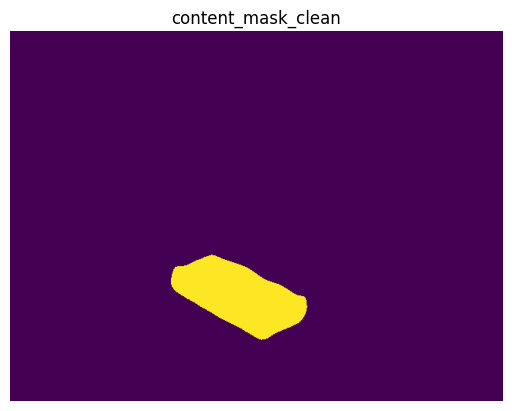

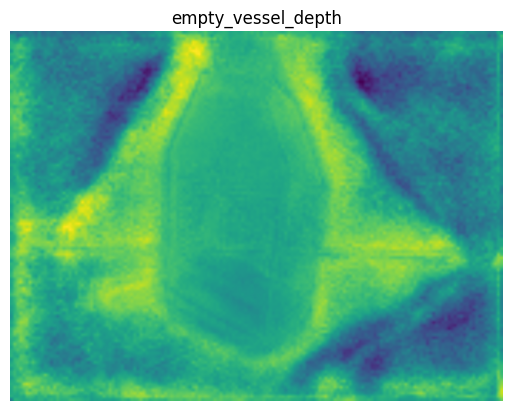

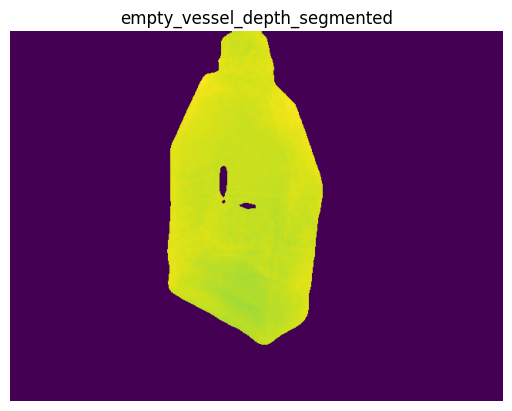

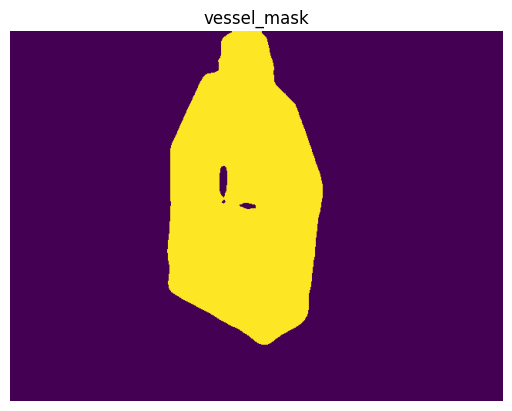

In [19]:
for key, value in sample.items():
    if isinstance(value, np.ndarray):
        img = value
        if img.ndim == 3 and img.shape[0] in (1, 3, 4) and img.shape[-1] not in (3, 4):
            img = np.transpose(img, (1, 2, 0))
        if img.ndim == 3 and img.shape[-1] == 1:
            img = img.squeeze(-1)
        plt.figure()
        if img.ndim == 2:
            plt.imshow(img, cmap="viridis")
        else:
            plt.imshow(img)
        plt.title(key)
        plt.axis("off")
plt.show()